# 03. Models and evaluation

**Goal:** rank prescribers so that an auditor who can review only a small share of them finds as many future exclusions as possible.

**Design**
- **Out-of-time evaluation.** Train on 2022 features (exclusions in 2023-2024), choose settings on 2023 (exclusions in 2024-2025), and report final results on 2024 (exclusions in 2025-2026), a year the model never saw.
- **Metrics that match the job.** With about 2 positives per 10,000 prescribers, accuracy is meaningless (predicting "nobody" is 99.98% accurate). We report **PR-AUC** (average precision) and, more concretely, **recall and lift when auditing the top 0.1%, 1% and 5%** of prescribers. Lift = how many times better than picking prescribers at random.
- **Uncertainty.** With a few hundred positives, metrics move a lot by chance, so we add 95% bootstrap intervals for the final numbers.

**Models compared**
1. **Random** ranking (the baseline every model must beat).
2. **Rule of thumb**: average peer percentile of the three strongest univariate signals from notebook 02 (dual-eligible share, low-income share, claims per patient).
3. **Unsupervised anomaly score** (Isolation Forest on the peer-comparison features): uses no labels at all, like a team starting without audit history.
4. **Supervised gradient-boosted trees** (LightGBM).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.ensemble import IsolationForest
from src.data import load_processed
from src.features import build_features, PEER_FEATURES
from src.evaluate import ranking_report, bootstrap_ci, psi

SEED = 0
data = {}
for y in (2022, 2023, 2024):
    lab = load_processed(f"labeled_{y}")
    if y < 2024:
        # Prescribers excluded after the label window are neither clean negatives nor positives
        # for that window, so they are left out of training and validation years.
        lab = lab[lab["excluded_later"] == 0].reset_index(drop=True)
    feats = build_features(lab)
    num = [c for c in feats.columns if c not in ("specialty", "state")]
    feats[num] = feats[num].astype("float32")
    data[y] = (feats, lab)

specialties = sorted(set().union(*[set(f["specialty"].cat.categories) for f, _ in data.values()]))
for f, _ in data.values():
    f["specialty"] = f["specialty"].astype(pd.CategoricalDtype(specialties))

NUM = [c for c in data[2022][0].columns if c not in ("specialty", "state")]
COLS = NUM + ["specialty"]
print({y: (len(f), int(l['label_any'].sum()), int(l['label_fraud'].sum())) for y, (f, l) in data.items()})

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{2022: (1331864, 309, 185), 2023: (1380435, 290, 146), 2024: (1416828, 268, 113)}


## Training with downsampled negatives

There are about 4,000 negatives per positive. We keep **all positives and a random 5% of negatives** for training. This speeds training about 20x and, for a ranking task, does not change which prescribers end up on top: it only shifts predicted probabilities, which we do not use as probabilities here.

In [2]:
def sample_train(feats, lab, label, frac_neg=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    keep = (lab[label].to_numpy() == 1) | (rng.random(len(lab)) < frac_neg)
    return feats[keep], lab[label].to_numpy()[keep]

PARAMS = dict(n_estimators=600, learning_rate=0.02, num_leaves=7, min_child_samples=100,
              subsample=0.7, subsample_freq=1, colsample_bytree=0.5, reg_lambda=10,
              cat_smooth=50, random_state=SEED, verbose=-1)

def fit_lgbm(X, y, cols=COLS):
    return lgb.LGBMClassifier(**PARAMS).fit(X[cols], y)

def show(results):
    keep = ["positives", "pr_auc", "pr_auc_lift", "roc_auc", "recall@0.1%", "recall@1%",
            "recall@5%", "lift@1%"]
    return pd.DataFrame(results).T[keep].astype(float).round(4)

## Step 1: compare approaches on the validation year (2023)

All models are fit on 2022 (or use no labels) and scored on 2023.

In [3]:
label = "label_any"
Xtr, ytr = sample_train(*data[2022], label)
Xva, yva = data[2023][0], data[2023][1][label].to_numpy()
rng = np.random.default_rng(SEED)

scores_va = {
    "random": rng.random(len(yva)),
    "rule of thumb": Xva[["dual_bene_share_peer_pct", "lis_claim_share_peer_pct",
                          "claims_per_bene_peer_pct"]].mean(axis=1).to_numpy(),
}
z_cols = [f"{c}_peer_z" for c in PEER_FEATURES]
iso = IsolationForest(n_estimators=200, max_samples=50_000, random_state=SEED)
iso.fit(data[2022][0][z_cols].fillna(0).sample(200_000, random_state=SEED))
scores_va["isolation forest (no labels)"] = -iso.score_samples(Xva[z_cols].fillna(0))
scores_va["LightGBM, rates only"] = fit_lgbm(Xtr, ytr, NUM).predict_proba(Xva[NUM])[:, 1]
scores_va["LightGBM, rates + specialty"] = fit_lgbm(Xtr, ytr).predict_proba(Xva[COLS])[:, 1]
show({k: ranking_report(yva, s) for k, s in scores_va.items()})

,positives,pr_auc,pr_auc_lift,roc_auc,recall@0.1%,recall@1%,recall@5%,lift@1%
random,290.0,0.0002,0.9869,0.4940,0.0000,0.0069,0.0483,0.6897
rule of thumb,290.0,0.0003,1.5575,0.5673,0.0000,0.0207,0.1172,2.0690
isolation forest (no labels),290.0,0.0004,1.8372,0.6177,0.0069,0.0414,0.1241,4.1380
"LightGBM, rates only",290.0,0.0020,9.4222,0.8025,0.0276,0.1828,0.3690,18.2763
"LightGBM, rates + specialty",290.0,0.0021,9.8203,0.8150,0.0310,0.1724,0.3690,17.2418


**Reading the table.** Random ranking finds about 1% of positives in the top 1% (lift 1). The unsupervised anomaly score and the simple rule both beat random, but the supervised model is clearly better: labels from past exclusions teach it which kinds of "unusual" matter. Adding specialty as a feature lets the model learn that base rates differ by specialty.

## Step 2: final model, tested on 2024

For the final model we train on 2022 **and** 2023 (more positives), then score 2024 prescribers and check who was excluded in 2025-2026. We do this for both label definitions.

In [4]:
final = {}
results = {}
for label in ("label_any", "label_fraud"):
    parts = [sample_train(*data[y], label) for y in (2022, 2023)]
    X = pd.concat([p[0] for p in parts]); yy = np.concatenate([p[1] for p in parts])
    model = fit_lgbm(X, yy)
    Xte, yte = data[2024][0], data[2024][1][label].to_numpy()
    s = model.predict_proba(Xte[COLS])[:, 1]
    final[label] = (model, s, yte)
    results[f"LightGBM, {label}"] = ranking_report(yte, s)
    results[f"random, {label}"] = ranking_report(yte, np.random.default_rng(SEED).random(len(yte)))
show(results)

,positives,pr_auc,pr_auc_lift,roc_auc,recall@0.1%,recall@1%,recall@5%,lift@1%
"LightGBM, label_any",268.0,0.0035,18.2831,0.8082,0.0522,0.1716,0.3396,17.1645
"random, label_any",268.0,0.0002,1.0131,0.5006,0.0000,0.0075,0.0485,0.7463
"LightGBM, label_fraud",113.0,0.0008,10.6133,0.8125,0.0354,0.1593,0.3717,15.9295
"random, label_fraud",113.0,0.0001,0.9987,0.4833,0.0000,0.0088,0.0442,0.8850


In [5]:
ci_rows = {}
for label, (model, s, yte) in final.items():
    for metric in ("recall@1%", "recall@5%", "lift@1%", "pr_auc_lift"):
        lo, hi = bootstrap_ci(yte, s, metric, n_boot=100)
        ci_rows[(label, metric)] = {"estimate": ranking_report(yte, s)[metric], "95% CI low": lo, "95% CI high": hi}
pd.DataFrame(ci_rows).T.round(3)

estimate  95% CI low  95% CI high
label_any   recall@1%       0.172       0.137        0.221
            recall@5%       0.340       0.296        0.399
            lift@1%        17.165      13.689       22.092
            pr_auc_lift    18.283       9.559       41.286
label_fraud recall@1%       0.159       0.106        0.235
            recall@5%       0.372       0.292        0.461
            lift@1%        15.930      10.624       23.524
            pr_auc_lift    10.613       6.989       21.596

## What this means for an audit team

Translate the test results into the decision an auditor faces: "if we can review N prescribers, how many future exclusions do we find?"

**Lift** = exclusions found by the model divided by the number a random selection of the same size would find. It is highest at the top of the list, where the model is most confident, and falls as the audit reaches further down, where prescribers look more like average. The 0.1% row rests on only 14 cases, so it is the noisiest; the 1% row is the most reliable headline (see the bootstrap interval above). 

In [6]:
model, s, yte = final["label_any"]
order = np.argsort(-s)
n = len(yte)
rows = []
for frac in (0.001, 0.005, 0.01, 0.02, 0.05, 0.10):
    k = int(n * frac)
    found = int(yte[order[:k]].sum())
    rows.append({"audit top": f"{frac:.1%}", "prescribers reviewed": k, "future exclusions found": found,
                 "share of all found": found / yte.sum(), "random would find": round(yte.mean() * k, 1),
                 "lift (x random)": round(found / (yte.mean() * k), 1)})
pd.DataFrame(rows).set_index("audit top").round(3)

,prescribers reviewed,future exclusions found,share of all found,random would find,lift (x random)
audit top,,,,,
0.1%,1416,14,0.052,0.3,52.3
0.5%,7084,33,0.123,1.3,24.6
1.0%,14168,46,0.172,2.7,17.2
2.0%,28336,60,0.224,5.4,11.2
5.0%,70841,91,0.340,13.4,6.8
10.0%,141682,125,0.466,26.8,4.7


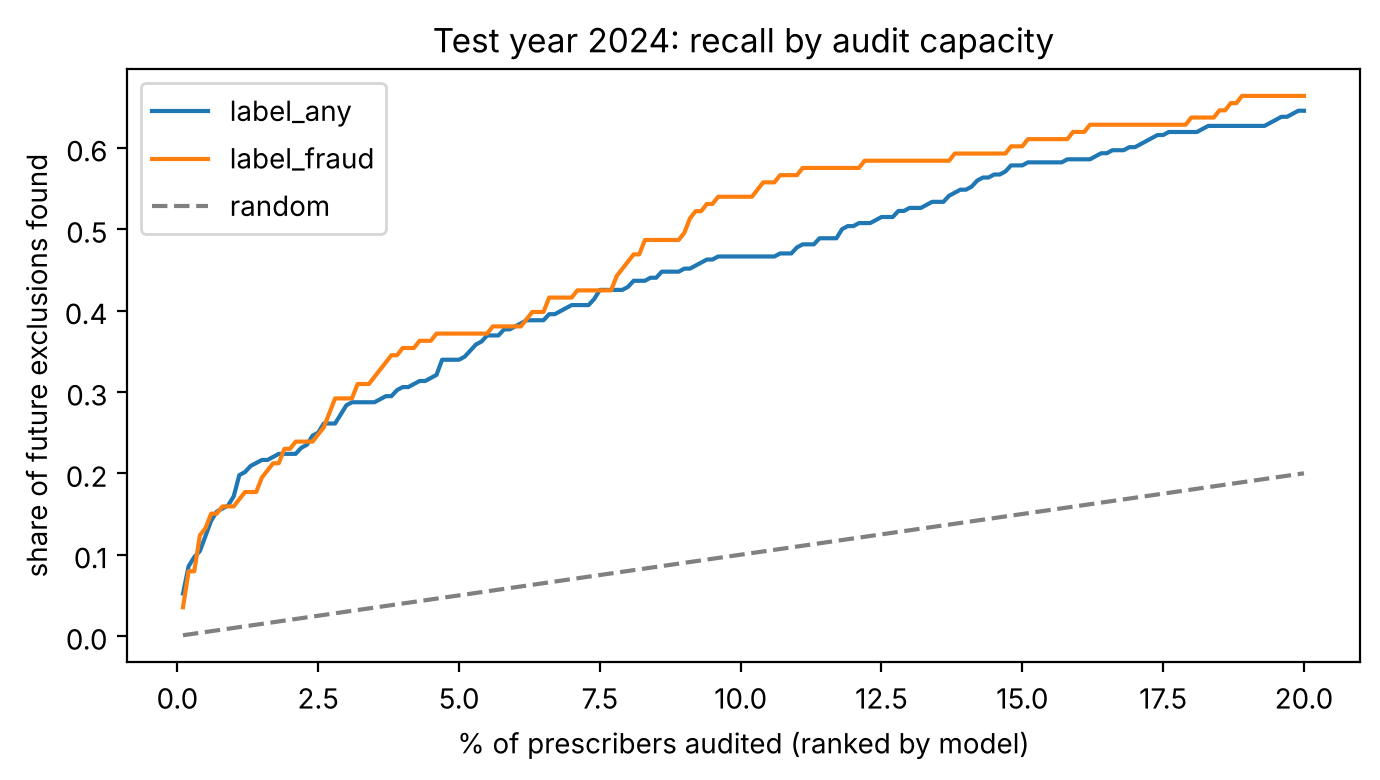

In [7]:
fracs = np.linspace(0.001, 0.2, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for label, (model, s_, y_) in final.items():
    order_ = np.argsort(-s_)
    cum = np.cumsum(y_[order_]) / y_.sum()
    ax.plot(fracs * 100, [cum[int(len(y_) * f) - 1] for f in fracs], label=label)
ax.plot(fracs * 100, fracs, "--", color="grey", label="random")
ax.set_xlabel("% of prescribers audited (ranked by model)")
ax.set_ylabel("share of future exclusions found")
ax.set_title("Test year 2024: recall by audit capacity")
ax.legend(); fig.tight_layout()

## Why the model flags a prescriber (SHAP)

SHAP values split each prediction into contributions from each feature. The summary below shows which features drive the ranking overall; for a single flagged prescriber the same values explain why they were flagged, which an auditor needs before opening a case.

/usr/local/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


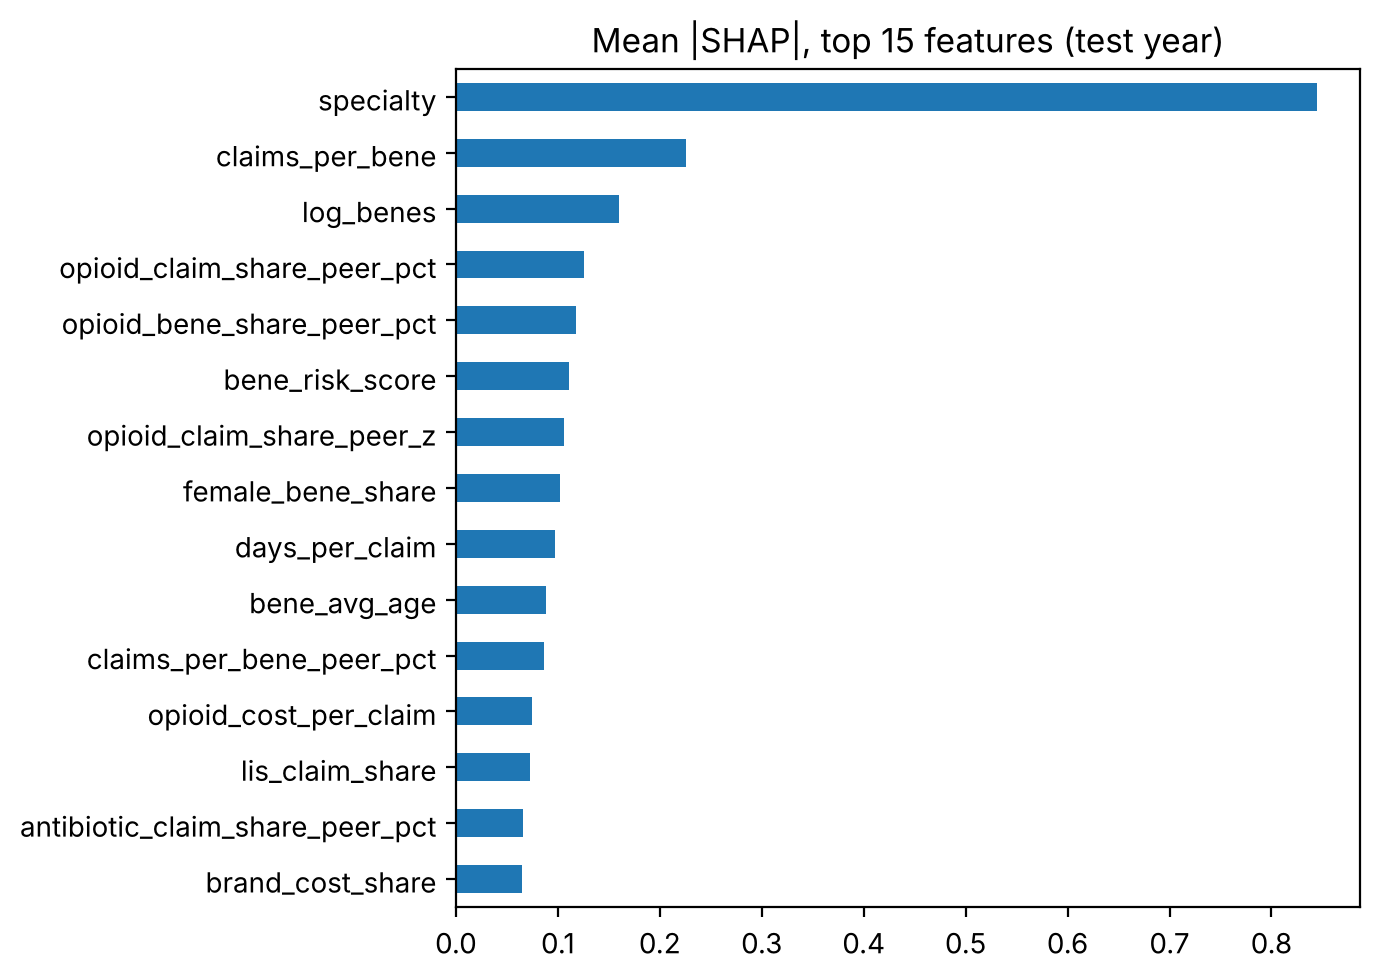

In [8]:
model, s, yte = final["label_any"]
Xte = data[2024][0]
top = np.argsort(-s)[:5000]
sample = Xte.iloc[np.concatenate([top, np.random.default_rng(SEED).choice(len(Xte), 5000, replace=False)])][COLS]
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
imp = pd.Series(np.abs(sv).mean(axis=0), index=COLS).sort_values(ascending=False)
imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title="Mean |SHAP|, top 15 features (test year)")
plt.tight_layout()

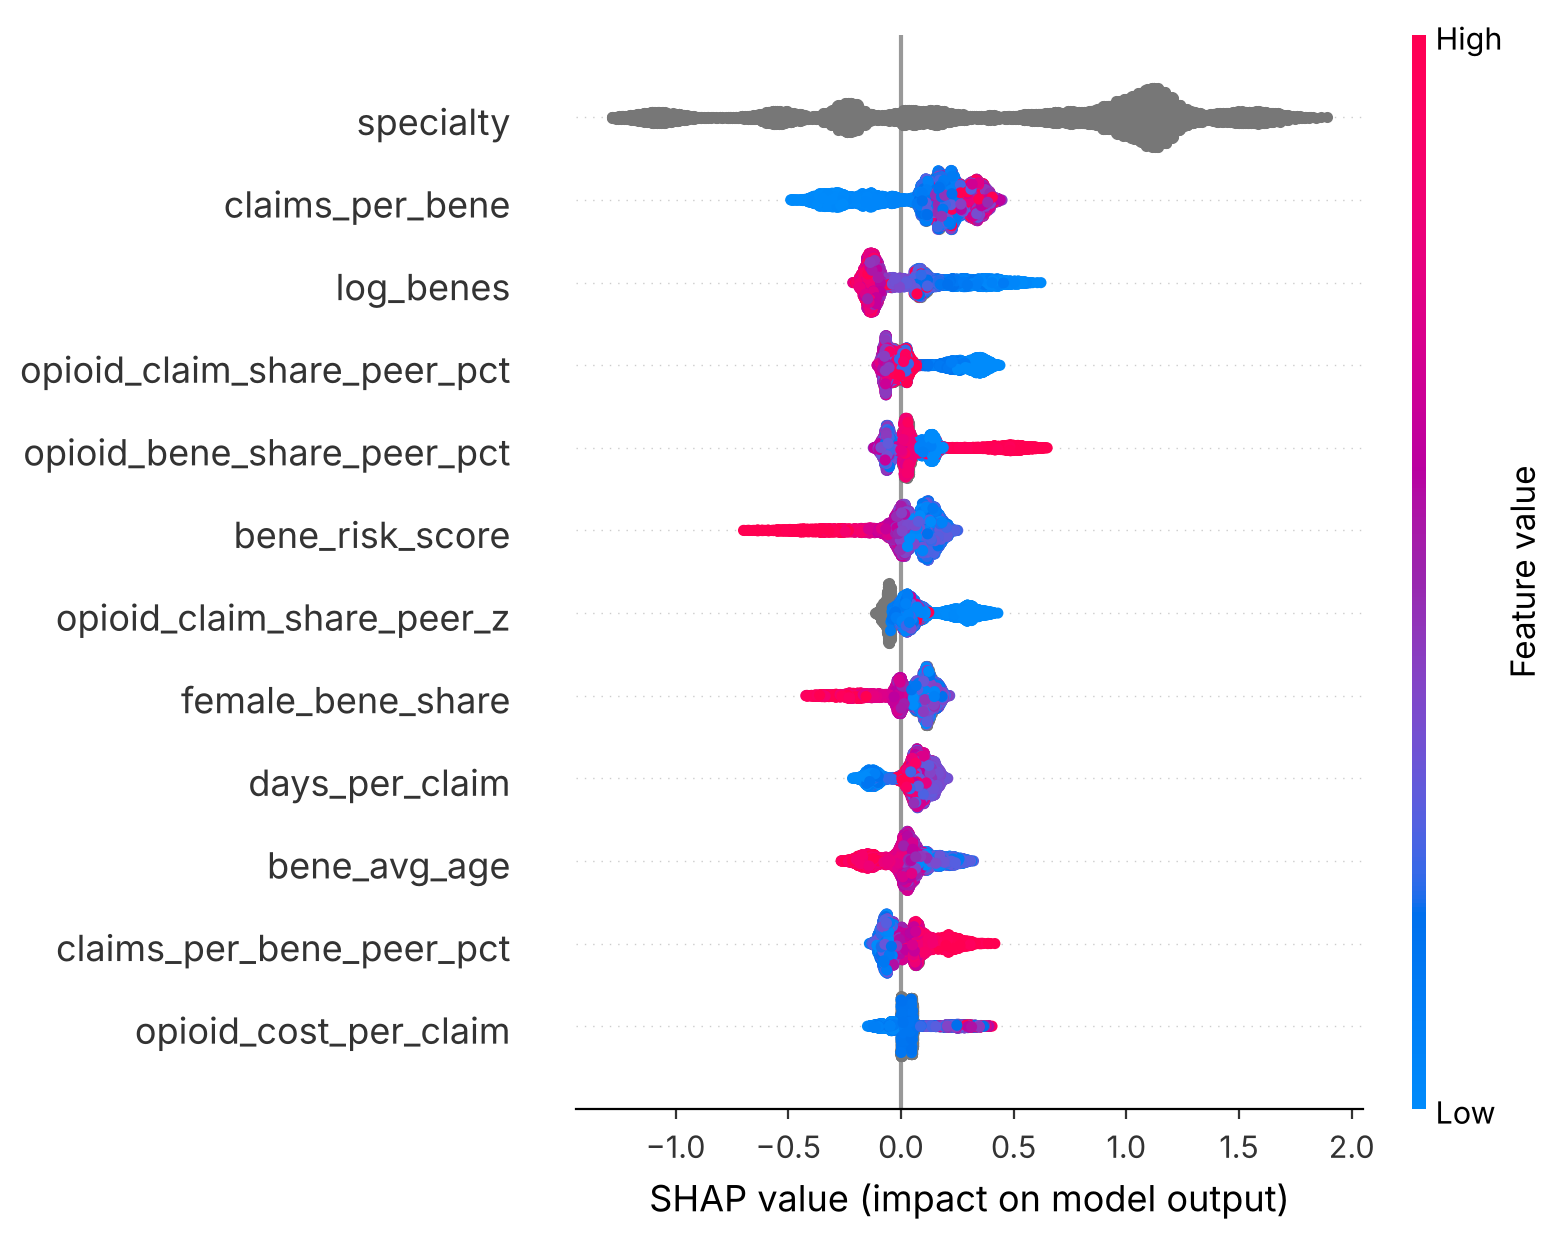

In [9]:
shap.summary_plot(sv, sample, max_display=12, show=False)
plt.tight_layout()

## Which specialties have the most exclusions?

Specialty is the most important feature in the model, so it is worth looking at directly. The table pools the three labeled years (2022-2024). Counts are **prescriber-years**: a prescriber can appear in more than one year's window. Rates are per 10,000 prescriber-years, shown only for specialties with at least 10,000 prescriber-years so that small groups do not produce extreme rates by chance.

Two different questions give two different answers:
- **Most exclusions in total:** Family Practice and Internal Medicine, simply because they are large specialties.
- **Highest rate:** Physical Medicine and Rehabilitation and General Practice, each with about 5 fraud-label exclusions per 10,000 prescriber-years, roughly 4.5 times the overall rate of 1.1. General Practice also has the highest rate for any exclusion (9.9 vs 2.1 overall). Pain management is often practiced within Physical Medicine and Rehabilitation, consistent with the role of opioid prescribing in the fraud label. These rates rest on small counts (14 fraud-label cases each), so they are indicative, not precise.

These are exclusion rates, not fraud rates: they reflect who was caught and excluded, and they say nothing about any individual prescriber.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
from src.data import load_processed

pooled = pd.concat([load_processed(f"labeled_{y}")[["Prscrbr_Type", "label_any", "label_fraud"]]
                    for y in (2022, 2023, 2024)])
by_spec = (pooled.groupby("Prscrbr_Type")
           .agg(prescriber_years=("label_any", "size"),
                excluded_any=("label_any", "sum"), excluded_fraud=("label_fraud", "sum")))
by_spec["any_per_10k"] = by_spec["excluded_any"] / by_spec["prescriber_years"] * 1e4
by_spec["fraud_per_10k"] = by_spec["excluded_fraud"] / by_spec["prescriber_years"] * 1e4
print(f"Overall: {pooled['label_any'].mean() * 1e4:.1f} (any) and "
      f"{pooled['label_fraud'].mean() * 1e4:.1f} (fraud) per 10,000 prescriber-years")
(by_spec[by_spec["prescriber_years"] >= 10_000]
 .sort_values("fraud_per_10k", ascending=False).head(10).round(1))

Overall: 2.1 (any) and 1.1 (fraud) per 10,000 prescriber-years


,prescriber_years,excluded_any,excluded_fraud,any_per_10k,fraud_per_10k
Prscrbr_Type,,,,,
Physical Medicine and Rehabilitation,27079,16,14,5.9,5.2
General Practice,27348,27,14,9.9,5.1
Psychiatry & Neurology,47876,28,15,5.8,3.1
Family Practice,349233,203,104,5.8,3.0
Anesthesiology,18676,8,5,4.3,2.7
Podiatry,47344,18,12,3.8,2.5
Allergy/ Immunology,11926,3,3,2.5,2.5
Otolaryngology,31930,13,8,4.1,2.5
Internal Medicine,384951,158,91,4.1,2.4


## Drift: is 2024 like 2022?

A model trained on past years assumes prescribing patterns stay similar. The population stability index (PSI) compares each feature's distribution in 2024 with 2022: below 0.1 is stable, 0.1-0.25 a moderate shift, above 0.25 a large shift.

In [10]:
drift = pd.Series({c: psi(data[2022][0][c], data[2024][0][c]) for c in imp.index[:15] if c != "specialty"})
drift.sort_values(ascending=False).round(3).rename("PSI 2022 vs 2024")

brand_cost_share                   0.111
opioid_cost_per_claim              0.074
opioid_bene_share_peer_pct         0.025
bene_avg_age                       0.017
bene_risk_score                    0.014
opioid_claim_share_peer_z          0.008
antibiotic_claim_share_peer_pct    0.008
opioid_claim_share_peer_pct        0.007
log_benes                          0.004
lis_claim_share                    0.001
days_per_claim                     0.001
female_bene_share                  0.000
claims_per_bene                    0.000
claims_per_bene_peer_pct           0.000
Name: PSI 2022 vs 2024, dtype: float64

## Takeaways

See the README for a summary of results. Key points to discuss with a claims-audit team:

- **Supervised beats unsupervised** here: "unusual" alone flags many legitimate outliers; past outcomes teach the model which unusual patterns matter.
- **Label choice matters.** The fraud-only label has fewer positives and is noisier to evaluate; the broad label includes exclusions unrelated to prescribing.
- **Precision stays low in absolute terms** because positives are so rare (about 2 per 10,000), but the lift over random is large, which is what decides whether an audit program pays off.
- **Limitations:** labels capture only providers who were caught and are still excluded; only about 10% of LEIE records have an NPI; Part D data is aggregated by year and released with an 18-month lag. With claim-level data and audit outcomes, the same framework would rank claims instead of prescribers.